# Experimento: Hiperparámetros del MLP

Notebook para determinar los hiperparámetros de `ModeloRedNeuronal`. La configuración elegida queda en los valores por defecto de la red neuronal en `src/modelos.py`.

Cada configuración se entrena 5 veces con los datos de 4 pacientes y se valida con el restante, sin repetir el paciente de validación. Ya que solo el 0.19% de las ventanas son crisis, para comparar los valores se utilizan AUC y precisión promedio además de validation loss.

In [1]:
import sys
from pathlib import Path

# Raíz del proyecto: El notebook se ejecuta desde notebooks/.
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import average_precision_score, roc_auc_score

from datos import cargar_pacientes
from modelos import ModeloRedNeuronal, ModeloUmbral

## Configuración

In [3]:
CARPETA_DATOS = RAIZ / "data" / "processed"
CARPETA_FIGURAS = RAIZ / "resultados"
CARPETA_FIGURAS.mkdir(exist_ok=True)

# Pacientes usados para entrenar y validar.
PACIENTES = ["chb01", "chb03", "chb04", "chb05", "chb09"]

# Valores iniciales de los hiperparámetros.
mejores = {"capas": [25], "tasa": 1e-3, "epocas": 50}

In [4]:
def separar(paciente: str) -> list:
    """Carga los demás pacientes para entrenar y el paciente dado para
    validar.

    Args:
        paciente (str): Paciente que se deja fuera del entrenamiento.

    Returns:
        list: Datasets de entrenamiento y validación.
    """
    otros = PACIENTES.copy()
    otros.remove(paciente)
    entrenamiento = cargar_pacientes(CARPETA_DATOS, otros)
    validacion = cargar_pacientes(CARPETA_DATOS, [paciente])
    return [entrenamiento, validacion]


def validar(parametros: dict) -> dict:
    """Valida una configuración con cada uno de los 5 pacientes.

    Args:
        parametros (dict): Capas, tasa de aprendizaje y épocas de la red.

    Returns:
        dict: Por paciente, train y validation loss de cada época, AUC y
        precisión promedio.
    """
    resultado = {
        "train_loss": [],
        "val_loss": [],
        "auc": [],
        "precision_promedio": [],
    }
    for paciente in PACIENTES:
        print(
            f"== Capas {parametros['capas']}, tasa {parametros['tasa']:g}, "
            f"{parametros['epocas']} épocas | Validación: {paciente} =="
        )
        entrenamiento, validacion = separar(paciente)
        red = ModeloRedNeuronal(
            parametros["capas"],
            parametros["tasa"],
            parametros["epocas"],
            validacion,
        )
        red.entrenar(entrenamiento)
        perdidas = red.obtener_perdidas()
        resultado["train_loss"].append(perdidas["train"])
        resultado["val_loss"].append(perdidas["validacion"])

        y = validacion.obtener_etiquetas()
        puntajes = red.calcular_puntaje(validacion.obtener_caracteristicas())
        resultado["auc"].append(roc_auc_score(y, puntajes))
        resultado["precision_promedio"].append(
            average_precision_score(y, puntajes)
        )
    return resultado


def media(valores: list) -> str:
    """Calcula la media y desviación estándar de una métrica entre pacientes.

    Args:
        valores (list): Un valor por paciente.

    Returns:
        str: Media +- desviación estándar, con 3 decimales.
    """
    return f"{np.mean(valores):.3f} ± {np.std(valores):.3f}"


def mostrar_fila(nombre: str, valores: list) -> None:
    """Muestra el valor por paciente y al final la media y desviación.

    Args:
        nombre (str): Nombre de la métrica, al inicio de la fila.
        valores (list): Valor de la métrica para cada paciente.
    """
    fila = f"{nombre:<30}"
    for valor in valores:
        fila += f"{valor:>8.3f}"
    print(f"{fila}{media(valores):>16}")


def probar(clave: str, valores: list) -> dict:
    """Valida cada valor de un hiperparámetro, dejando fijos los demás, y
    muestra una tabla con la media y desviación por métrica.

    Args:
        clave (str): Nombre del hiperparámetro ("capas", "tasa" o "epocas").
        valores (list): Valores del hiperparámetro.

    Returns:
        dict: Train loss, validation loss, AUC y precisión promedio de cada
        valor probado.
    """
    resultados = {}
    for valor in valores:
        parametros = mejores.copy()
        parametros[clave] = valor
        resultados[str(valor)] = validar(parametros)

    # Se imprime la tabla al final para que no quede entre las salidas del
    # entrenamiento.
    print()
    print(
        f"{clave:<10}{'Train loss':>15}{'Val loss':>15}{'AUC':>15}"
        f"{'Precisión promedio':>20}"
    )
    for valor, resultado in resultados.items():
        # Train y validation loss de la última época, por paciente de
        # validación.
        train_loss = np.array(resultado["train_loss"])[:, -1].tolist()
        val_loss = np.array(resultado["val_loss"])[:, -1].tolist()
        print(
            f"{valor:<10}{media(train_loss):>15}{media(val_loss):>15}"
            f"{media(resultado['auc']):>15}"
            f"{media(resultado['precision_promedio']):>20}"
        )
    return resultados

In [5]:
def graficar(resultados: dict, leyendas: list, archivo: str) -> None:
    """Grafica train y validation loss de cada época (media entre los
    pacientes de validación) para los valores probados, y guarda la figura
    en resultados/.

    Args:
        resultados (dict): Train y validation loss de cada valor probado.
        leyendas (list): Una leyenda por valor.
        archivo (str): Nombre del archivo de la figura.
    """
    figura, ejes = plt.subplots(1, 2, figsize=(12, 4))
    valores = list(resultados)
    for i in range(len(valores)):
        train_loss = np.mean(resultados[valores[i]]["train_loss"], axis=0)
        val_loss = np.mean(resultados[valores[i]]["val_loss"], axis=0)
        epocas = np.arange(1, len(train_loss) + 1)
        ejes[0].plot(epocas, train_loss, label=leyendas[i])
        ejes[1].plot(epocas, val_loss, label=leyendas[i])
    ejes[0].set_ylabel("Train loss")
    ejes[1].set_ylabel("Validation loss")
    for eje in ejes:
        eje.set_xlabel("Epoch")
        # Eje de épocas solo con marcas enteras.
        eje.xaxis.set_major_locator(
            MaxNLocator(integer=True, steps=[1, 2, 5, 10])
        )
        eje.grid(True)
        eje.legend()
    figura.tight_layout()
    figura.savefig(CARPETA_FIGURAS / archivo, dpi=300)
    plt.show()

## Capas ocultas

In [6]:
resultados_capas = probar("capas", [[12], [25], [50], [25, 12], [50, 25]])

== Capas [12], tasa 0.001, 50 épocas | Validación: chb01 ==
Epoch 1/50 - Train loss: 0.9666 - Val loss: 1.0381
Epoch 2/50 - Train loss: 0.7929 - Val loss: 0.9395
Epoch 3/50 - Train loss: 0.7176 - Val loss: 0.8199
Epoch 4/50 - Train loss: 0.6329 - Val loss: 0.7768
Epoch 5/50 - Train loss: 0.5641 - Val loss: 0.7370
Epoch 6/50 - Train loss: 0.5102 - Val loss: 0.7149
Epoch 7/50 - Train loss: 0.4751 - Val loss: 0.6987
Epoch 8/50 - Train loss: 0.4517 - Val loss: 0.6916
Epoch 9/50 - Train loss: 0.4359 - Val loss: 0.7011
Epoch 10/50 - Train loss: 0.4197 - Val loss: 0.7150
Epoch 11/50 - Train loss: 0.4072 - Val loss: 0.7145
Epoch 12/50 - Train loss: 0.4009 - Val loss: 0.7277
Epoch 13/50 - Train loss: 0.3923 - Val loss: 0.7481
Epoch 14/50 - Train loss: 0.3819 - Val loss: 0.7364
Epoch 15/50 - Train loss: 0.3724 - Val loss: 0.7666
Epoch 16/50 - Train loss: 0.3693 - Val loss: 0.7867
Epoch 17/50 - Train loss: 0.3632 - Val loss: 0.7805
Epoch 18/50 - Train loss: 0.3531 - Val loss: 0.7969
Epoch 19/50 -

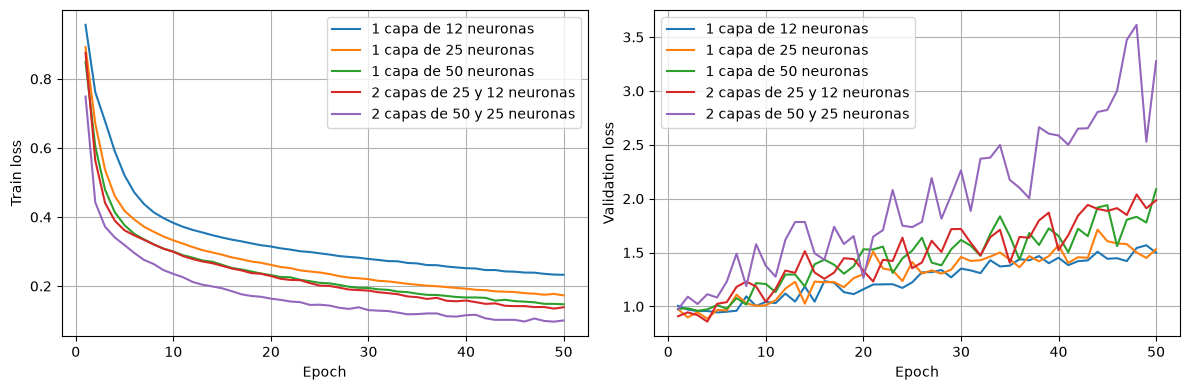

In [16]:
graficar(
    resultados_capas,
    [
        "1 capa de 12 neuronas",
        "1 capa de 25 neuronas",
        "1 capa de 50 neuronas",
        "2 capas de 25 y 12 neuronas",
        "2 capas de 50 y 25 neuronas",
    ],
    "experimento_mlp_01_capas.png",
)

Se usa `[25]`; `[12]` solo mejora en validation loss y `[25, 12]` únicamente en AUC, mientras que `[25]` además entrega la mejor precisión promedio.


In [8]:
mejores["capas"] = [25]

## Tasa de aprendizaje


In [9]:
resultados_tasa = probar("tasa", [1e-4, 1e-3, 1e-2])

== Capas [25], tasa 0.0001, 50 épocas | Validación: chb01 ==
Epoch 1/50 - Train loss: 1.2181 - Val loss: 1.4935
Epoch 2/50 - Train loss: 1.0049 - Val loss: 1.2508
Epoch 3/50 - Train loss: 0.9264 - Val loss: 1.1630
Epoch 4/50 - Train loss: 0.8887 - Val loss: 1.1191
Epoch 5/50 - Train loss: 0.8622 - Val loss: 1.0859
Epoch 6/50 - Train loss: 0.8409 - Val loss: 1.0582
Epoch 7/50 - Train loss: 0.8217 - Val loss: 1.0425
Epoch 8/50 - Train loss: 0.8033 - Val loss: 1.0281
Epoch 9/50 - Train loss: 0.7859 - Val loss: 1.0037
Epoch 10/50 - Train loss: 0.7685 - Val loss: 0.9765
Epoch 11/50 - Train loss: 0.7516 - Val loss: 0.9661
Epoch 12/50 - Train loss: 0.7341 - Val loss: 0.9382
Epoch 13/50 - Train loss: 0.7169 - Val loss: 0.9212
Epoch 14/50 - Train loss: 0.7001 - Val loss: 0.9132
Epoch 15/50 - Train loss: 0.6833 - Val loss: 0.9000
Epoch 16/50 - Train loss: 0.6675 - Val loss: 0.8899
Epoch 17/50 - Train loss: 0.6520 - Val loss: 0.8736
Epoch 18/50 - Train loss: 0.6373 - Val loss: 0.8685
Epoch 19/50 

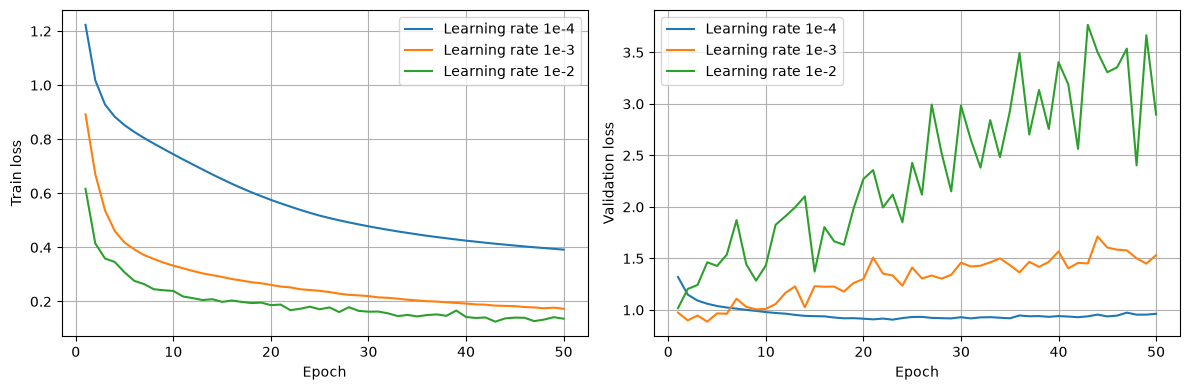

In [17]:
graficar(
    resultados_tasa,
    ["Learning rate 1e-4", "Learning rate 1e-3", "Learning rate 1e-2"],
    "experimento_mlp_02_tasa.png",
)

`1e-4` es mejor en las tres métricas.

In [11]:
mejores["tasa"] = 1e-4

## Épocas

Se entrena hasta 100 épocas con las capas y tasa de aprendizaje escogidas.

In [12]:
resultados_epocas = probar("epocas", [100])

== Capas [25], tasa 0.0001, 100 épocas | Validación: chb01 ==
Epoch 1/100 - Train loss: 1.2181 - Val loss: 1.4935
Epoch 2/100 - Train loss: 1.0049 - Val loss: 1.2508
Epoch 3/100 - Train loss: 0.9264 - Val loss: 1.1630
Epoch 4/100 - Train loss: 0.8887 - Val loss: 1.1191
Epoch 5/100 - Train loss: 0.8622 - Val loss: 1.0859
Epoch 6/100 - Train loss: 0.8409 - Val loss: 1.0582
Epoch 7/100 - Train loss: 0.8217 - Val loss: 1.0425
Epoch 8/100 - Train loss: 0.8033 - Val loss: 1.0281
Epoch 9/100 - Train loss: 0.7859 - Val loss: 1.0037
Epoch 10/100 - Train loss: 0.7685 - Val loss: 0.9765
Epoch 11/100 - Train loss: 0.7516 - Val loss: 0.9661
Epoch 12/100 - Train loss: 0.7341 - Val loss: 0.9382
Epoch 13/100 - Train loss: 0.7169 - Val loss: 0.9212
Epoch 14/100 - Train loss: 0.7001 - Val loss: 0.9132
Epoch 15/100 - Train loss: 0.6833 - Val loss: 0.9000
Epoch 16/100 - Train loss: 0.6675 - Val loss: 0.8899
Epoch 17/100 - Train loss: 0.6520 - Val loss: 0.8736
Epoch 18/100 - Train loss: 0.6373 - Val loss: 

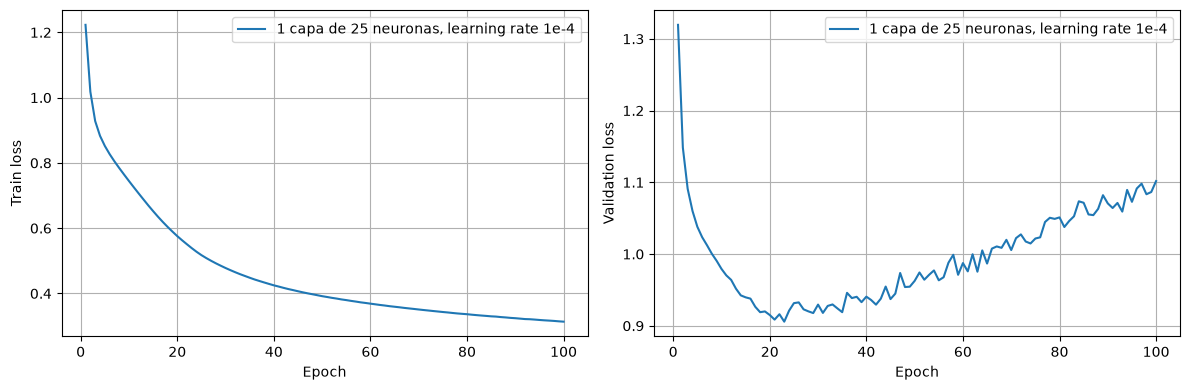

In [18]:
graficar(
    resultados_epocas,
    ["1 capa de 25 neuronas, learning rate 1e-4"],
    "experimento_mlp_03_epocas.png",
)

La media de validation loss es mínima en la época 23.

In [14]:
mejores["epocas"] = 23

## Configuración elegida

In [15]:
# Se valida la red con la configuración elegida en cada paciente.
mlp = validar(mejores)

# El puntaje del modelo umbral no depende del entrenamiento; su AUC y
# precisión promedio se calculan directamente en cada paciente.
umbral = {"auc": [], "precision_promedio": []}
for paciente in PACIENTES:
    dataset = cargar_pacientes(CARPETA_DATOS, [paciente])
    y = dataset.obtener_etiquetas()
    puntajes = ModeloUmbral().calcular_puntaje(
        dataset.obtener_caracteristicas()
    )
    umbral["auc"].append(roc_auc_score(y, puntajes))
    umbral["precision_promedio"].append(average_precision_score(y, puntajes))

print()
print(mejores)
encabezado = f"{'Métrica':<30}"
for paciente in PACIENTES:
    encabezado += f"{paciente:>8}"
print(f"{encabezado}{'Media':>16}")
mostrar_fila("AUC umbral", umbral["auc"])
mostrar_fila("AUC MLP", mlp["auc"])
mostrar_fila("Precisión promedio umbral", umbral["precision_promedio"])
mostrar_fila("Precisión promedio MLP", mlp["precision_promedio"])

== Capas [25], tasa 0.0001, 23 épocas | Validación: chb01 ==
Epoch 1/23 - Train loss: 1.2181 - Val loss: 1.4935
Epoch 2/23 - Train loss: 1.0049 - Val loss: 1.2508
Epoch 3/23 - Train loss: 0.9264 - Val loss: 1.1630
Epoch 4/23 - Train loss: 0.8887 - Val loss: 1.1191
Epoch 5/23 - Train loss: 0.8622 - Val loss: 1.0859
Epoch 6/23 - Train loss: 0.8409 - Val loss: 1.0582
Epoch 7/23 - Train loss: 0.8217 - Val loss: 1.0425
Epoch 8/23 - Train loss: 0.8033 - Val loss: 1.0281
Epoch 9/23 - Train loss: 0.7859 - Val loss: 1.0037
Epoch 10/23 - Train loss: 0.7685 - Val loss: 0.9765
Epoch 11/23 - Train loss: 0.7516 - Val loss: 0.9661
Epoch 12/23 - Train loss: 0.7341 - Val loss: 0.9382
Epoch 13/23 - Train loss: 0.7169 - Val loss: 0.9212
Epoch 14/23 - Train loss: 0.7001 - Val loss: 0.9132
Epoch 15/23 - Train loss: 0.6833 - Val loss: 0.9000
Epoch 16/23 - Train loss: 0.6675 - Val loss: 0.8899
Epoch 17/23 - Train loss: 0.6520 - Val loss: 0.8736
Epoch 18/23 - Train loss: 0.6373 - Val loss: 0.8685
Epoch 19/23 